In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (2240, 29)


In [5]:
print(df.head())


     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0

In [6]:
print(df.shape)

(2240, 29)


In [7]:
print(df.columns)

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [9]:
print(df.isnull().sum())

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


In [10]:
print(df.describe())

                 ID   Year_Birth         Income      Kidhome     Teenhome  \
count   2240.000000  2240.000000    2216.000000  2240.000000  2240.000000   
mean    5592.159821  1968.805804   52247.251354     0.444196     0.506250   
std     3246.662198    11.984069   25173.076661     0.538398     0.544538   
min        0.000000  1893.000000    1730.000000     0.000000     0.000000   
25%     2828.250000  1959.000000   35303.000000     0.000000     0.000000   
50%     5458.500000  1970.000000   51381.500000     0.000000     0.000000   
75%     8427.750000  1977.000000   68522.000000     1.000000     1.000000   
max    11191.000000  1996.000000  666666.000000     2.000000     2.000000   

           Recency     MntWines    MntFruits  MntMeatProducts  \
count  2240.000000  2240.000000  2240.000000      2240.000000   
mean     49.109375   303.935714    26.302232       166.950000   
std      28.962453   336.597393    39.773434       225.715373   
min       0.000000     0.000000     0.000000  

In [13]:
data = df.copy()

data["Dt_Customer"] = pd.to_datetime(
    data["Dt_Customer"],
    dayfirst=True,
    errors="coerce"
)

latest_date = data["Dt_Customer"].max()

data["Customer_Tenure_Days"] = (
    latest_date - data["Dt_Customer"]
).dt.days


In [14]:
data = data.drop(
    columns=[
        "ID",
        "Dt_Customer",
        "Z_CostContact",
        "Z_Revenue",
        "Response"
    ]
)

In [15]:
print(data.head())

   Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  Recency  \
0        1957  Graduation         Single  58138.0        0         0       58   
1        1954  Graduation         Single  46344.0        1         1       38   
2        1965  Graduation       Together  71613.0        0         0       26   
3        1984  Graduation       Together  26646.0        1         0       26   
4        1981         PhD        Married  58293.0        1         0       94   

   MntWines  MntFruits  MntMeatProducts  ...  NumCatalogPurchases  \
0       635         88              546  ...                   10   
1        11          1                6  ...                    1   
2       426         49              127  ...                    2   
3        11          4               20  ...                    0   
4       173         43              118  ...                    3   

   NumStorePurchases  NumWebVisitsMonth  AcceptedCmp3  AcceptedCmp4  \
0                  4       

In [16]:
print(data.shape)

(2240, 25)


In [17]:
numeric_cols = data.select_dtypes(include=np.number).columns

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

In [18]:
categorical_cols = data.select_dtypes(include="object").columns

for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

In [19]:
print(data.isnull().sum().sum())

0


In [20]:
scaler = StandardScaler()

data[numeric_cols] = scaler.fit_transform(data[numeric_cols])

print(data.head())

   Year_Birth   Education Marital_Status    Income   Kidhome  Teenhome  \
0   -0.985345  Graduation         Single  0.235696 -0.825218 -0.929894   
1   -1.235733  Graduation         Single -0.235454  1.032559  0.906934   
2   -0.317643  Graduation       Together  0.773999 -0.825218 -0.929894   
3    1.268149  Graduation       Together -1.022355  1.032559 -0.929894   
4    1.017761         PhD        Married  0.241888  1.032559 -0.929894   

    Recency  MntWines  MntFruits  MntMeatProducts  ...  NumCatalogPurchases  \
0  0.307039  0.983781   1.551577         1.679702  ...             2.510890   
1 -0.383664 -0.870479  -0.636301        -0.713225  ...            -0.568720   
2 -0.798086  0.362723   0.570804        -0.177032  ...            -0.226541   
3 -0.798086 -0.870479  -0.560857        -0.651187  ...            -0.910898   
4  1.550305 -0.389085   0.419916        -0.216914  ...             0.115638   

   NumStorePurchases  NumWebVisitsMonth  AcceptedCmp3  AcceptedCmp4  \
0        

In [21]:
data = pd.get_dummies(
    data,
    columns=list(categorical_cols),
    dtype=int
)

print(data.head())
print("Data shape:", data.shape)

   Year_Birth    Income   Kidhome  Teenhome   Recency  MntWines  MntFruits  \
0   -0.985345  0.235696 -0.825218 -0.929894  0.307039  0.983781   1.551577   
1   -1.235733 -0.235454  1.032559  0.906934 -0.383664 -0.870479  -0.636301   
2   -0.317643  0.773999 -0.825218 -0.929894 -0.798086  0.362723   0.570804   
3    1.268149 -1.022355  1.032559 -0.929894 -0.798086 -0.870479  -0.560857   
4    1.017761  0.241888  1.032559 -0.929894  1.550305 -0.389085   0.419916   

   MntMeatProducts  MntFishProducts  MntSweetProducts  ...  Education_Master  \
0         1.679702         2.462147          1.476500  ...                 0   
1        -0.713225        -0.650449         -0.631503  ...                 0   
2        -0.177032         1.345274         -0.146905  ...                 0   
3        -0.651187        -0.503974         -0.583043  ...                 0   
4        -0.216914         0.155164         -0.001525  ...                 0   

   Education_PhD  Marital_Status_Absurd  Marital_S

In [22]:
X = data.values

print("Missing values:", data.isnull().sum().sum())
print("Data shape:", data.shape)
print("Feature matrix shape:", X.shape)

Missing values: 0
Data shape: (2240, 36)
Feature matrix shape: (2240, 36)


In [23]:
kmeans_first = KMeans(n_clusters=4, random_state=42, n_init=10)

first_labels = kmeans_first.fit_predict(X)

print("Initial K-Means cluster sizes:")
print(pd.Series(first_labels).value_counts().sort_index())

Initial K-Means cluster sizes:
0      30
1     634
2    1038
3     538
Name: count, dtype: int64


In [24]:
inertias = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

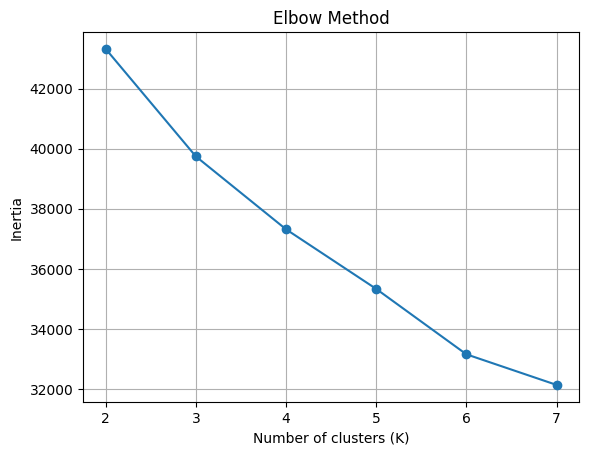

In [25]:
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [26]:
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

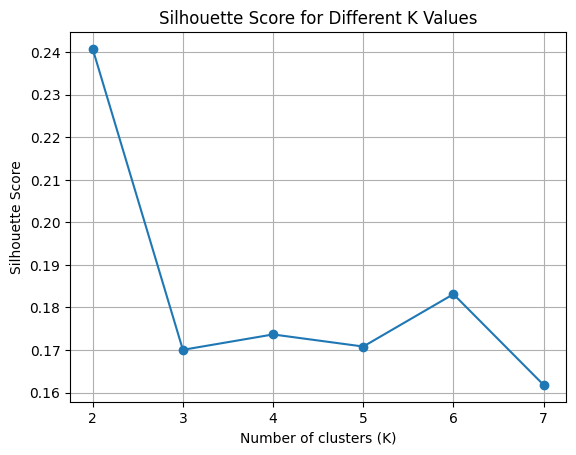

In [27]:
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [28]:
k = 4

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X)

results = df.copy()
results["KMeans_Cluster"] = kmeans_labels

print("Final K-Means cluster sizes:")
print(results["KMeans_Cluster"].value_counts().sort_index())

print("\nSilhouette Score:", round(silhouette_score(X, kmeans_labels), 3))

Final K-Means cluster sizes:
KMeans_Cluster
0      30
1     634
2    1038
3     538
Name: count, dtype: int64

Silhouette Score: 0.174


In [29]:
summary_cols = [
    "Income", "MntWines", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
    "Recency"
]

print("Average customer values for each K-Means cluster:")
display(results.groupby("KMeans_Cluster")[summary_cols].mean().round(1))

Average customer values for each K-Means cluster:


,Income,MntWines,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Recency
KMeans_Cluster,,,,,,,,,,,
0,71054.8,898.7,250.3,38.7,30.6,66.4,4.9,5.2,8.2,5.2,48.7
1,58088.1,456.0,140.2,32.1,24.9,60.2,6.4,3.1,7.8,5.7,48.4
2,34908.5,42.0,23.5,7.0,5.1,15.4,2.1,0.6,3.2,6.4,49.4
3,77694.1,597.1,470.6,102.6,71.9,79.0,5.1,6.1,8.3,2.7,49.5
